# TOPSIS ranking of gasification operating conditions

Ranks the simulated operating conditions by their gasification performance using TOPSIS (Technique for Order of Preference by Similarity to Ideal Solution).

Each **alternative** is one set of operating conditions (pressure, ER, MC, temperature). Each is scored on four **performance criteria**, the simulated outputs:

| Criterion | Meaning | Direction |
|---|---|---|
| H2 (%) | Hydrogen concentration in the syngas | Higher is better |
| LHV (MJ/kmol) | Lower heating value of the syngas | Higher is better |
| η (%) | Gasification efficiency | Higher is better |
| λ (g/mol) | Normalised CO₂ emission | Lower is better |

The operating conditions identify the alternatives but are not criteria themselves. In this dataset all four conditions rise together along one operating path, so ranking on the conditions would only reproduce the order of the path.

**Data.** The simulation table is confidential and is not included in this repository. Place it at `data/gasification_simulation.csv` to run the notebook.

## 1. Setup

Requires Python 3.11 or later for [PyMCDM](https://github.com/kotbaton/pymcdm), which provides the TOPSIS implementation (`pip install -r requirements.txt`).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymcdm.methods import TOPSIS
from pymcdm.normalizations import vector_normalization

DATA_PATH = Path("data") / "gasification_simulation.csv"
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Weighting scheme used for the main ranking: "Equal", "Standard deviation" or "CRITIC"
MAIN_WEIGHTING = "Equal"

## 2. Input data

In [2]:
data = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
data.columns = data.columns.astype(str).str.strip()
data = data.rename(columns={
    "Pressure (kPa)": "Pressure",
    "MC (wt%)": "MC",
    "Temperature (°C)": "Temperature",
    "H2 (%)": "H2",
    "LHV (MJ/kmol)": "LHV",
    "η (%)": "η",
    "λ (g/mol)": "λ",
})

conditions = ["Pressure", "ER", "MC", "Temperature"]
criteria = ["H2", "LHV", "η", "λ"]
criteria_types = pd.Series({"H2": 1, "LHV": 1, "η": 1, "λ": -1})  # 1 benefit, -1 cost

if not data.columns.is_unique:
    raise ValueError("Duplicate column names after renaming the dataset headers.")
missing_columns = set(conditions + criteria) - set(data.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {', '.join(sorted(missing_columns))}")

data = data[conditions + criteria].apply(pd.to_numeric, errors="raise")
if not np.isfinite(data.to_numpy()).all():
    raise ValueError("The dataset contains missing or non-finite values.")
if (data[criteria] <= 0).any().any():
    raise ValueError("Vector normalisation below assumes strictly positive criteria.")

print(f"Dataset: {len(data)} simulation runs")

Dataset: 10000 simulation runs


## 3. Alternatives

Some operating conditions appear more than once in the table. Their outputs differ only in the last rounded digit, so repeated runs are averaged and each operating condition is ranked once.

The *sweep position* (0 at the start of the operating path, 1 at the end) is the mean of the four conditions, each rescaled to 0–1. It is used only to plot results along the path.

In [3]:
alternatives = (
    data.groupby(conditions, sort=True)
    .agg(**{c: (c, "mean") for c in criteria}, Runs=("H2", "size"))
    .reset_index()
)
largest_spread = data.groupby(conditions)[criteria].agg(np.ptp).max()
print(f"Alternatives (unique operating conditions): {len(alternatives)}")
print(f"Conditions with repeated runs: {(alternatives['Runs'] > 1).sum()}")
print("Largest output spread within repeated runs:", largest_spread.round(4).to_dict())

condition_ranges = data[conditions].max() - data[conditions].min()
alternatives["Sweep_position"] = (
    (alternatives[conditions] - data[conditions].min()) / condition_ranges
).mean(axis=1)

Alternatives (unique operating conditions): 9221
Conditions with repeated runs: 778
Largest output spread within repeated runs: {'H2': 0.01, 'LHV': 0.1, 'η': 0.01, 'λ': 0.01}


### Trade-off between the criteria

The criteria do not peak at the same point on the path. η is highest early, H2 late, while LHV falls and λ (an emission, so lower is better) rises along the whole path. This conflict is what TOPSIS resolves. The correlation table shows that LHV, η and λ largely move together, while H2 pulls the other way.

Correlation between criteria:
        H2    LHV      η      λ
H2   1.000 -0.909 -0.545  0.811
LHV -0.909  1.000  0.844 -0.981
η   -0.545  0.844  1.000 -0.932
λ    0.811 -0.981 -0.932  1.000


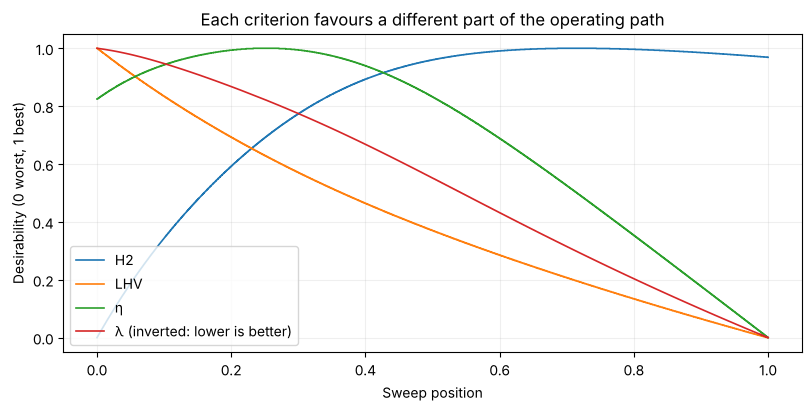

In [4]:
print("Correlation between criteria:")
print(alternatives[criteria].corr().round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for name in criteria:
    values = alternatives[name]
    desirability = (values - values.min()) / (values.max() - values.min())
    if criteria_types[name] == -1:
        desirability = 1 - desirability
    label = f"{name} (inverted: lower is better)" if criteria_types[name] == -1 else name
    ax.plot(alternatives["Sweep_position"], desirability, lw=1.2, label=label)
ax.set(xlabel="Sweep position", ylabel="Desirability (0 worst, 1 best)",
       title="Each criterion favours a different part of the operating path")
ax.legend()
ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / "topsis_criteria_tradeoff.png", dpi=160)
plt.show()

### Non-dominated alternatives

An alternative is *dominated* if another one is at least as good on every criterion and better on at least one. Dominated alternatives can never be a sensible choice, whatever the weights, so the best TOPSIS alternative should be among the non-dominated ones.

In [5]:
def non_dominated_mask(matrix, types, block_size=500):
    # True for rows that no other row dominates (larger is better after orientation).
    oriented = matrix * types
    keep = np.ones(len(oriented), dtype=bool)
    for start in range(0, len(oriented), block_size):
        block = oriented[start:start + block_size, None, :]
        at_least_as_good = (oriented[None, :, :] >= block).all(axis=2)
        strictly_better = (oriented[None, :, :] > block).any(axis=2)
        keep[start:start + block_size] = ~(at_least_as_good & strictly_better).any(axis=1)
    return keep


decision_matrix = alternatives[criteria].to_numpy(dtype=float)
types = criteria_types[criteria].to_numpy()

alternatives["Non_dominated"] = non_dominated_mask(decision_matrix, types)
front = alternatives.loc[alternatives["Non_dominated"], "Sweep_position"]
print(f"Non-dominated alternatives: {len(front)} of {len(alternatives)}")
print(f"They lie between sweep positions {front.min():.3f} and {front.max():.3f}")

Non-dominated alternatives: 1805 of 9221
They lie between sweep positions 0.000 and 0.686


## 4. Criterion weights

Three weighting schemes are compared. Each starts from min–max normalised criteria (0 worst, 1 best), so the weights do not depend on units or on where a scale starts.

- **Equal**: every criterion counts the same (0.25 each).
- **Standard deviation**: criteria that vary more across the alternatives get more weight.
- **CRITIC**: like standard deviation, but also lowers the weight of criteria that are strongly correlated with the others, so information shared by several criteria is not counted several times. Here LHV, η and λ largely carry the same information, so H2 gains weight.

The main ranking uses the scheme set in `MAIN_WEIGHTING`. Section 6 shows how the result changes with the others.

In [6]:
span = decision_matrix.max(axis=0) - decision_matrix.min(axis=0)
if (span <= 0).any():
    raise ValueError("Every criterion must vary across the alternatives.")
desirability = (decision_matrix - decision_matrix.min(axis=0)) / span
desirability[:, types == -1] = 1 - desirability[:, types == -1]

spread = desirability.std(axis=0, ddof=0)
correlation = np.corrcoef(desirability, rowvar=False)
critic_information = spread * (1 - correlation).sum(axis=0)

weight_table = pd.DataFrame({
    "Direction": ["Benefit" if t == 1 else "Cost" for t in types],
    "Equal": np.full(len(criteria), 1 / len(criteria)),
    "Standard deviation": spread / spread.sum(),
    "CRITIC": critic_information / critic_information.sum(),
}, index=pd.Index(criteria, name="Criterion"))
weighting_schemes = ["Equal", "Standard deviation", "CRITIC"]
if MAIN_WEIGHTING not in weighting_schemes:
    raise ValueError(f"MAIN_WEIGHTING must be one of {weighting_schemes}")
weight_table.round(4)

,Direction,Equal,Standard deviation,CRITIC
Criterion,,,,
H2,Benefit,0.25,0.2288,0.4497
LHV,Benefit,0.25,0.2392,0.1861
η,Benefit,0.25,0.2667,0.1761
λ,Cost,0.25,0.2654,0.1881


## 5. TOPSIS ranking

TOPSIS vector-normalises each criterion, applies the weights, and measures each alternative's distance to an ideal point (best value of every criterion) and an anti-ideal point (worst value of every criterion). The score is the relative closeness to the ideal: 1 is best, 0 is worst. Ties share a rank.

PyMCDM computes the scores. A short NumPy implementation of the same steps checks them.

In [7]:
def topsis_scores(matrix, weights, types):
    return TOPSIS(normalization_function=vector_normalization)(matrix, weights, types)


def topsis_reference(matrix, weights, types):
    weighted = matrix / np.linalg.norm(matrix, axis=0) * weights
    ideal = np.where(types == 1, weighted.max(axis=0), weighted.min(axis=0))
    anti_ideal = np.where(types == 1, weighted.min(axis=0), weighted.max(axis=0))
    to_ideal = np.linalg.norm(weighted - ideal, axis=1)
    to_anti_ideal = np.linalg.norm(weighted - anti_ideal, axis=1)
    return to_anti_ideal / (to_ideal + to_anti_ideal)


scores = {}
for scheme in weighting_schemes:
    weights = weight_table[scheme].to_numpy()
    scores[scheme] = topsis_scores(decision_matrix, weights, types)
    np.testing.assert_allclose(
        scores[scheme], topsis_reference(decision_matrix, weights, types), atol=1e-10
    )

ranking = alternatives.assign(TOPSIS_score=scores[MAIN_WEIGHTING])
ranking["Rank"] = ranking["TOPSIS_score"].rank(ascending=False, method="min").astype(int)
ranking = ranking.sort_values(["Rank", "Sweep_position"], kind="stable").reset_index(drop=True)
assert ranking.loc[0, "Non_dominated"], "The top alternative should be non-dominated."

display_columns = ["Rank"] + conditions + criteria + ["TOPSIS_score", "Runs"]
print(f"Main ranking: {MAIN_WEIGHTING} weights")
print("\nTen best operating conditions:")
print(ranking[display_columns].head(10).round(4).to_string(index=False))
print("\nTen worst operating conditions:")
print(ranking[display_columns].tail(10).round(4).to_string(index=False))

Main ranking: Equal weights

Ten best operating conditions:
 Rank  Pressure     ER     MC  Temperature    H2   LHV     η     λ  TOPSIS_score  Runs
    1     275.7 0.3195 0.1390        758.6 12.81 146.4 96.26 1.390        0.8010     1
    2     272.9 0.3192 0.1384        757.6 12.73 146.6 96.25 1.363        0.8010     1
    3     274.0 0.3193 0.1387        758.0 12.76 146.5 96.26 1.373        0.8009     1
    4     276.8 0.3196 0.1393        758.9 12.84 146.3 96.26 1.400        0.8009     1
    5     275.4 0.3195 0.1390        758.5 12.80 146.4 96.26 1.387        0.8009     1
    6     270.5 0.3189 0.1379        756.8 12.66 146.8 96.25 1.340        0.8009     1
    7     273.0 0.3192 0.1384        757.7 12.73 146.6 96.25 1.364        0.8009     1
    8     273.6 0.3193 0.1386        757.9 12.75 146.5 96.26 1.370        0.8009     1
    9     276.4 0.3196 0.1392        758.8 12.83 146.3 96.26 1.397        0.8009     1
   10     274.1 0.3193 0.1387        758.0 12.76 146.5 96.26 1.374    

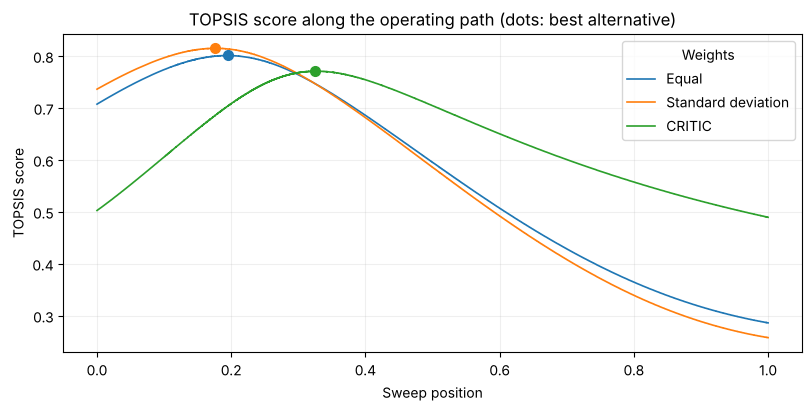

In [8]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for scheme in weighting_schemes:
    line, = ax.plot(alternatives["Sweep_position"], scores[scheme], lw=1.2, label=scheme)
    best = np.argmax(scores[scheme])
    ax.plot(alternatives["Sweep_position"].iloc[best], scores[scheme][best], "o",
            color=line.get_color(), ms=7)
ax.set(xlabel="Sweep position", ylabel="TOPSIS score",
       title="TOPSIS score along the operating path (dots: best alternative)")
ax.legend(title="Weights")
ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / "topsis_scores.png", dpi=160)
plt.show()

## 6. Sensitivity to the weights

TOPSIS results depend on the weights, so the best operating condition is compared across the three schemes, together with the Spearman rank correlation of each full ranking with the main one.

In [9]:
best_rows = []
for scheme in weighting_schemes:
    best = int(np.argmax(scores[scheme]))
    row = alternatives.iloc[best]
    best_rows.append({
        "Weights": scheme,
        **{c: row[c] for c in conditions + criteria},
        "Sweep_position": row["Sweep_position"],
        "TOPSIS_score": scores[scheme][best],
        "Rank_correlation_with_main": pd.Series(scores[scheme]).corr(
            pd.Series(scores[MAIN_WEIGHTING]), method="spearman"),
    })
best_by_weighting = pd.DataFrame(best_rows)
print(best_by_weighting.round(4).to_string(index=False))

           Weights  Pressure     ER     MC  Temperature    H2   LHV     η     λ  Sweep_position  TOPSIS_score  Rank_correlation_with_main
             Equal     275.7 0.3195 0.1390        758.6 12.81 146.4 96.26 1.390          0.1951        0.8010                      1.0000
Standard deviation     258.3 0.3176 0.1352        752.8 12.30 147.7 96.21 1.225          0.1760        0.8148                      0.9972
            CRITIC     392.4 0.3325 0.1650        797.5 15.50 138.2 96.21 2.618          0.3250        0.7709                      0.6751


H2 is the only criterion that favours the later part of the path, so its weight decides where the best condition lies. Below, the H2 weight is varied while LHV, η and λ share the remaining weight equally.

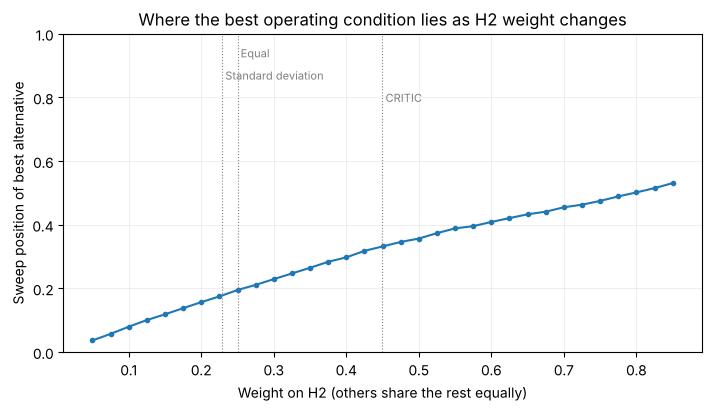

In [10]:
h2_weights = np.linspace(0.05, 0.85, 33)
best_positions = []
for h2_weight in h2_weights:
    weights = np.full(len(criteria), (1 - h2_weight) / (len(criteria) - 1))
    weights[criteria.index("H2")] = h2_weight
    best = np.argmax(topsis_scores(decision_matrix, weights, types))
    best_positions.append(alternatives["Sweep_position"].iloc[best])

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(h2_weights, best_positions, "-o", ms=3)
for i, scheme in enumerate(weighting_schemes):
    ax.axvline(weight_table.loc["H2", scheme], color="grey", lw=0.8, ls=":")
    ax.text(weight_table.loc["H2", scheme], 0.96 - 0.07 * i, f" {scheme}",
            va="top", fontsize=8, color="grey")
ax.set(xlabel="Weight on H2 (others share the rest equally)",
       ylabel="Sweep position of best alternative", ylim=(0, 1),
       title="Where the best operating condition lies as H2 weight changes")
ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / "topsis_h2_weight_sensitivity.png", dpi=160)
plt.show()

## 7. Summary

With this dataset:

- The best operating conditions lie in the early-to-middle part of the operating path, where efficiency is near its peak, LHV is still high and CO₂ emission is low, at the cost of a lower H2 concentration.
- The end of the path ranks worst. H2 is highest there, but LHV and efficiency are lowest and CO₂ emission is highest.
- Equal and standard-deviation weights give almost the same ranking. CRITIC weights, which correct for LHV, η and λ carrying overlapping information, move the best condition further along the path towards higher H2.
- The best condition should therefore be read as a region whose position depends on how much hydrogen yield is valued against energy content, efficiency and emissions, rather than as one exact run.

## 8. Export

Weights, the best condition per weighting scheme and the figures are written to `results/`. The full ranking is not exported because it reproduces the confidential dataset.

In [11]:
weight_table.to_csv(OUTPUT_DIR / "topsis_weights.csv")
best_by_weighting.to_csv(OUTPUT_DIR / "topsis_best_by_weighting.csv", index=False)
print("Saved TOPSIS weights, best conditions and figures to", OUTPUT_DIR)

Saved TOPSIS weights, best conditions and figures to results
